Load Data

In [1]:
import sys
import os
sys.path.append(os.path.abspath(".."))

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../data/processed/dataset_final.csv")
df = df.sort_values("date")

dates = pd.to_datetime(df["date"])
df_model = df.drop(columns=["date"])

Load Model & Scaller

In [4]:
import joblib

model = tf.keras.models.load_model("../model/model_eks1/lstm_model.keras")
scaler = joblib.load("../model/model_eks1/scaler.save")

d:\project_skripsi\.venv\lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 7 variables whereas the saved optimizer has 12 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Inverse scalling test set

In [5]:
# ambil prediksi terakhir dari modeling
y_test = np.load("../model/model_eks1/y_test.npy")
y_pred = np.load("../model/model_eks1/y_pred.npy")

# inverse scaling (khusus kolom IHSG saja)
ihsg_min = scaler.data_min_[0]
ihsg_max = scaler.data_max_[0]

y_test_real = y_test * (ihsg_max - ihsg_min) + ihsg_min
y_pred_real = y_pred.flatten() * (ihsg_max - ihsg_min) + ihsg_min

Multi step forecast ke depan

In [6]:
future_steps = 250
window_size = 30

last_window = scaler.transform(df_model.values)[-window_size:]
last_window = last_window.reshape(1, window_size, df_model.shape[1])

future_predictions = []

for _ in range(future_steps):
    next_pred = model.predict(last_window)
    future_predictions.append(next_pred[0,0])

    # geser window
    next_input = last_window[0,1:]
    next_input = np.vstack((next_input, 
                            np.append(next_pred, 
                                      last_window[0,-1,1:])))

    last_window = next_input.reshape(1, window_size, df_model.shape[1])

d:\project_skripsi\.venv\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 360ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 300ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━

In [7]:
future_predictions_real = np.array(future_predictions) * (ihsg_max - ihsg_min) + ihsg_min

plot proyeksi

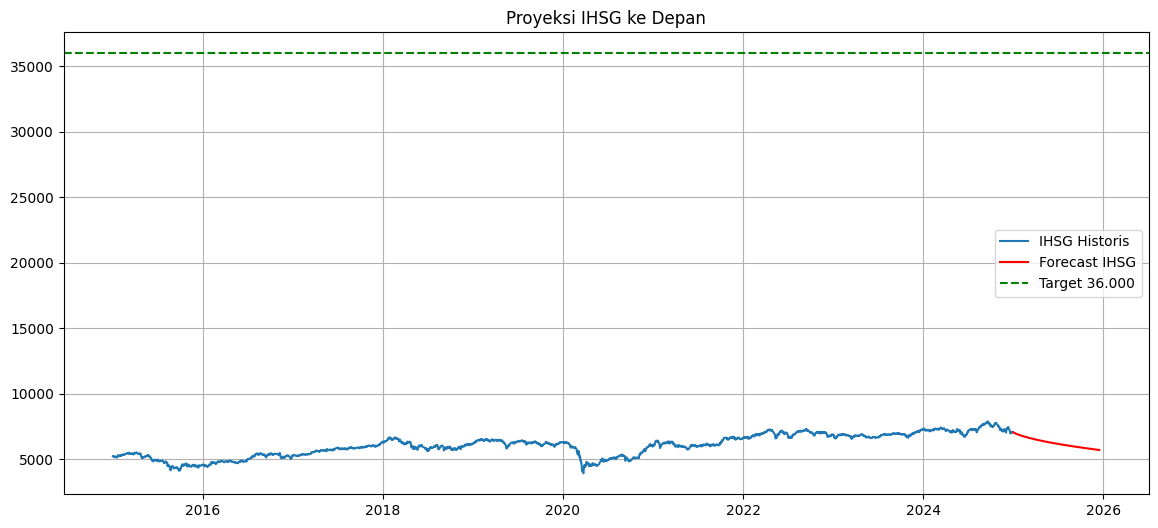

In [8]:
plt.figure(figsize=(14,6))

plt.plot(dates, df["ihsg"], label="IHSG Historis")

future_dates = pd.date_range(
    start=dates.iloc[-1],
    periods=future_steps+1,
    freq="B"
)[1:]

plt.plot(future_dates, future_predictions_real, 
         label="Forecast IHSG", color="red")

plt.axhline(36000, color="green", linestyle="--", label="Target 36.000")

plt.title("Proyeksi IHSG ke Depan")
plt.legend()
plt.grid(True)
plt.show()

estimasi tercapai target

In [9]:
target = 36000

cross_index = np.where(future_predictions_real >= target)[0]

if len(cross_index) > 0:
    cross_day = future_dates[cross_index[0]]
    print("IHSG diproyeksikan mencapai 36.000 pada:", cross_day)
else:
    print("Dalam horizon prediksi, IHSG belum mencapai 36.000")

Dalam horizon prediksi, IHSG belum mencapai 36.000


coba test aja

In [10]:
future_steps = 252 * 10
window_size = 30

# Ambil window terakhir
scaled_full = scaler.transform(df_model)
last_window = scaled_full[-window_size:]
last_window = last_window.reshape(1, window_size, df_model.shape[1])

future_predictions = []

for _ in range(future_steps):
    next_pred = model.predict(last_window, verbose=0)
    future_predictions.append(next_pred[0, 0])

    next_input = last_window[0, 1:]
    next_row = np.hstack((next_pred[0], last_window[0, -1, 1:]))

    last_window = np.vstack((next_input, next_row))
    last_window = last_window.reshape(1, window_size, df_model.shape[1])

future_predictions = np.array(future_predictions)

In [11]:
ihsg_min = scaler.data_min_[0]
ihsg_max = scaler.data_max_[0]

future_real = future_predictions * (ihsg_max - ihsg_min) + ihsg_min

In [12]:
future_dates = pd.date_range(
    start=pd.to_datetime(df["date"].iloc[-1]),
    periods=future_steps+1,
    freq="B"
)[1:]

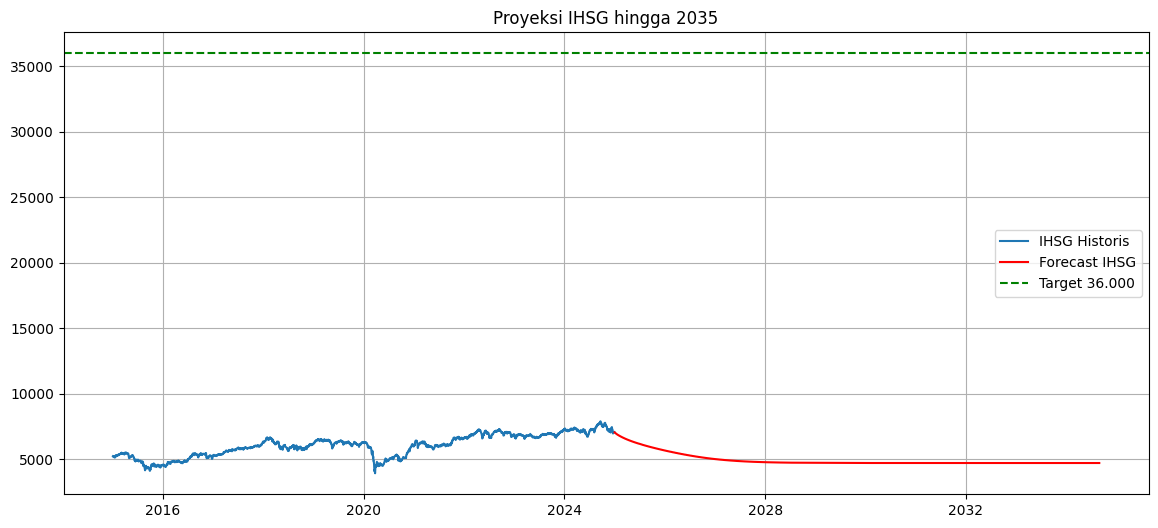

In [13]:
plt.figure(figsize=(14,6))

plt.plot(pd.to_datetime(df["date"]), df["ihsg"], label="IHSG Historis")
plt.plot(future_dates, future_real, label="Forecast IHSG", color="red")

plt.axhline(36000, color="green", linestyle="--", label="Target 36.000")

plt.title("Proyeksi IHSG hingga 2035")
plt.legend()
plt.grid(True)
plt.show()

test

In [14]:
future_real
future_dates

DatetimeIndex(['2024-12-31', '2025-01-01', '2025-01-02', '2025-01-03',
               '2025-01-06', '2025-01-07', '2025-01-08', '2025-01-09',
               '2025-01-10', '2025-01-13',
               ...
               '2034-08-15', '2034-08-16', '2034-08-17', '2034-08-18',
               '2034-08-21', '2034-08-22', '2034-08-23', '2034-08-24',
               '2034-08-25', '2034-08-28'],
              dtype='datetime64[ns]', length=2520, freq='B')

In [15]:
# Cari index nilai tertinggi
max_idx = np.argmax(future_real)

# Ambil nilai & tanggalnya
max_value = future_real[max_idx]
max_date = future_dates[max_idx]

print("Nilai tertinggi forecast :", round(max_value, 2))
print("Tanggal tercapai         :", max_date)

Nilai tertinggi forecast : 7057.03
Tanggal tercapai         : 2024-12-31 00:00:00
